In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = spark.read.table("workspace.messy_e_commerce.messy_ecommerce_orders").toPandas()
raw_df = df

In [0]:
print(f'Row Count: {raw_df.shape[0]}')
print(f'Column Count: {raw_df.shape[1]}')
print(f'Column names: {raw_df.columns.tolist()}')
print(f'Unique column names: {raw_df.columns.is_unique}')
print(f'Duplicate rows: {raw_df.duplicated().sum()}')
print(f'Column datatype:\n{raw_df.dtypes}')

Row Count: 329
Column Count: 10
Column names: ['order_id', 'order_date', 'customer_id', 'city', 'category', 'unit_price', 'quantity', 'discount_pct', 'order_status', 'payment_method']
Unique column names: True
Duplicate rows: 7
Column datatype:
order_id          object
order_date        object
customer_id       object
city              object
category          object
unit_price        object
quantity          object
discount_pct      object
order_status      object
payment_method    object
dtype: object


In [0]:
#  Column Profile

cols = raw_df.columns
rows =[]
for i in cols:
    rows.append({
        'column': i,
        'dtype': str(raw_df[i].dtypes),
        'missing values' : int(raw_df[i].isna().sum()),
        'non-missing values' : int(raw_df[i].notna().sum()),
        'missing pct' : round(float(raw_df[i].isna().mean()*100),2),
        'unique non-missing' : int(raw_df[i].nunique(dropna=True)),
        'unique pct' : round(float(raw_df[i].nunique(dropna=True)/len(raw_df))*100.0, 2)})
    col_profile = pd.DataFrame(rows)
display(col_profile.sort_values(["missing pct", "unique non-missing"], ascending=[False, False]))

column,dtype,missing values,non-missing values,missing pct,unique non-missing,unique pct
customer_id,object,7,322,2.13,124,37.69
unit_price,object,3,326,0.91,297,90.27
order_date,object,3,326,0.91,236,71.73
city,object,2,327,0.61,24,7.29
category,object,2,327,0.61,19,5.78
payment_method,object,1,328,0.3,20,6.08
discount_pct,object,1,328,0.3,14,4.26
order_id,object,0,329,0.0,320,97.26
quantity,object,0,329,0.0,17,5.17
order_status,object,0,329,0.0,13,3.95


In [0]:
print(f'Duplicate order_id: {raw_df.duplicated(subset='order_id').sum()}')
print(f'Blank order_id rows: {raw_df['order_id'].isna().sum()}')
keep = raw_df['order_id'].duplicated(keep=False) & raw_df['order_id'].notna()
show = raw_df.loc[keep].sort_values('order_id')
show

Duplicate order_id: 9
Blank order_id rows: 0


,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method
21,ORD-010023,2026/01/04,CUST-0047,Hyderabad,None,7079,1,10,delivered,Debit Card
320,ORD-010023,2026/01/04,CUST-0047,Hyderabad,None,7079,1,10,delivered,Debit Card
44,ORD-010046,10/09/2025,CUST-0011,Bengaluru,Electronics,NA,1,10,Delivered,UPI
325,ORD-010046,10/09/2025,CUST-0011,Bengaluru,Electronics,NA,2,10,Delivered,UPI
88,ORD-010090,10-Aug-2025,CUST-0039,Jaipur,Beauty,538,2,20,Delivered,Debit Card
321,ORD-010090,10-Aug-2025,CUST-0039,Jaipur,Beauty,538,2,20,Delivered,Debit Card
116,ORD-010118,2025-12-18,None,Mumbai,Clothing,664,1,15,Returned,UPI
326,ORD-010118,2025-12-18,None,Mumbai,Clothing,664,1,15,Returned,UPI
147,ORD-010149,2025/08/29,CUST-0047,Delhi,Home & Kitchen,5582,unknown,15,Delivered,UPI
322,ORD-010149,2025/08/29,CUST-0047,Delhi,Home & Kitchen,5582,unknown,15,Delivered,UPI


In [0]:
ignore_columns = ['order_id', 'customer_id', 'order_date']
for i in cols:
    if i in ignore_columns:
        continue
    else:
        s = raw_df[i]
        print(f'--- {i} | dtype: {s.dtype} | unique values: {s.nunique()}\n{s.value_counts().head(30)}\n')

--- city | dtype: object | unique values: 24
city
Delhi         58
Bengaluru     43
Jaipur        42
Hyderabad     40
Mumbai        38
Lucknow       35
Pune          28
hyderabad      6
Bombay         5
lucknow        4
PUNE           3
mumbai         3
BENGALURU      3
HYDERABAD      3
bangalore      3
pune           2
New Delhi      2
LUCKNOW        2
new delhi      2
unknown        1
Bangalore      1
 MUMBAI        1
DELHI          1
NA             1
Name: count, dtype: int64

--- category | dtype: object | unique values: 19
category
Grocery             81
Clothing            67
Electronics         54
Home & Kitchen      53
Beauty              46
Apparel              4
electronics          3
 Groceries           2
CLOTHING             2
ELECTRONICS          2
Electronic           2
BEAUTY               2
Personal Care        2
home & kitchen       2
Home and Kitchen     1
unknown              1
clothing             1
grocery              1
NA                   1
Name: count, dtype: 

##Data Cleaning

In [0]:
def string_na_cleaning(data):
    s = data.astype('string').str.strip()
    missing_tokens = ['','unknown', 'nan', 'na', 'np', 'n/a', 'null', 'none']
    lower = s.str.casefold().isin(missing_tokens)
    return s.mask(lower, pd.NA)

def string_cleaning(data, alias = None):
    new_data = string_na_cleaning(data)
    new_data = new_data.str.title()
    alias = alias or {}
    alias = {str(k).strip().title():v for k, v in alias.items()}
    return new_data.replace(alias)

In [0]:
def num_cleaning(data, alias = None):
    n = data.astype('string').str.strip()
    missing_tokens = ['','unknown', 'nan', 'na', 'np', 'n/a', 'null', 'none']
    lower = n.str.casefold().isin(missing_tokens)
    n = n.mask(lower, pd.NA)

    n = n.str.replace("%", "", regex=False)
    n = n.str.replace("$", "", regex=False)
    n = n.str.replace("₹", "", regex=False).str.replace("Rs.", "", regex=False)
    n = n.str.replace(",", "", regex=False).str.strip()

    alias = alias or {}
    alias = {str(k).strip().title():v for k, v in alias.items()}
    n = n.replace(alias)
    
    return pd.to_numeric(n, errors='coerce')

In [0]:
def date_cleaning(data):
    return pd.to_datetime(data, errors='coerce', format='mixed')

In [0]:
df_clean = raw_df

df_clean['order_id'] = string_cleaning(raw_df['order_id']).str.upper()
df_clean['customer_id'] = string_cleaning(raw_df['customer_id']).str.upper()

df_clean['order_date'] = date_cleaning(raw_df['order_date'])

city_alias = {'New Delhi':'Delhi', 'Bengaluru':'Bangalore', 'Bombay':'Mumbai'}
df_clean['city'] = string_cleaning(raw_df['city'], alias = city_alias)

category_alias = {'Home and Kitchen': 'Home & Kitchen', 'Groceries': 'Grocery','Electronic':'Electronics', 'Electronicss':'Electronics'}
df_clean['category'] = string_cleaning(raw_df['category'], alias = category_alias)

df_clean['unit_price'] = num_cleaning(raw_df['unit_price'])

quantity_alias = {'two':2}
df_clean['quantity'] = num_cleaning(raw_df['quantity'], alias = quantity_alias)

df_clean['discount_pct'] = num_cleaning(raw_df['discount_pct'])

order_status_alias = {'cancel':'Cancelled'}
df_clean['order_status'] = string_cleaning(raw_df['order_status'], alias = order_status_alias)

payment_method_alias = {'cc':'Credit Card', 'dc': 'Debit Card', 'upi': 'UPI', 'cod':'Cash On Delivery'}
df_clean['payment_method'] = string_cleaning(raw_df['payment_method'], alias = payment_method_alias)

In [0]:
#  Clean Data Inspectiom
ignore_columns = ['order_id', 'customer_id', 'order_date']
for i in cols:
    if i in ignore_columns:
        continue
    else:
        s = df_clean[i]
        print(f'--- {i} | dtype: {s.dtype} | unique values: {s.nunique()}\n{s.value_counts().head(30)}\n')
df_clean

--- city | dtype: string | unique values: 7
city
Delhi        63
Bangalore    50
Hyderabad    49
Mumbai       47
Jaipur       42
Lucknow      41
Pune         33
Name: count, dtype: Int64

--- category | dtype: string | unique values: 7
category
Grocery           84
Clothing          70
Electronics       61
Home & Kitchen    56
Beauty            48
Apparel            4
Personal Care      2
Name: count, dtype: Int64

--- unit_price | dtype: Float64 | unique values: 294
unit_price
48.0      3
567.0     2
64.0      2
35.0      2
41.0      2
599.0     2
97.0      2
538.0     2
91.0      2
664.0     2
50.0      2
73.0      2
5582.0    2
105.0     2
2283.0    2
67.0      2
185.0     2
40.0      2
79.0      2
26.0      2
4721.0    2
4661.0    2
1047.0    2
59.0      2
62.0      2
7079.0    2
1795.0    1
152.0     1
2377.0    1
2314.0    1
Name: count, dtype: Int64

--- quantity | dtype: Int64 | unique values: 13
quantity
1     157
2      75
3      31
4      22
5      16
8       8
6       6
10 

,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method
0,ORD-010002,2025-10-03,CUST-0095,Bangalore,Clothing,567.0,1,15,Delivered,UPI
1,ORD-010003,2025-08-06,CUST-0005,Mumbai,Electronics,6519.0,1,10,Pending,Cash On Delivery
2,ORD-010004,2026-01-31,CUST-0008,Jaipur,Clothing,1618.0,4,<NA>,Delivered,<NA>
3,ORD-010005,2025-08-11,CUST-0176,Pune,Grocery,20.0,2,15,Delivered,UPI
4,ORD-010006,2025-08-30,CUST-0103,Delhi,Clothing,1228.0,2,<NA>,Delivered,Cash On Delivery
...,...,...,...,...,...,...,...,...,...,...
324,ORD-010293,2025-12-10,<NA>,Delhi,Clothing,1047.0,4,25,Cancelled,Cash On Delivery
325,ORD-010046,2025-10-09,CUST-0011,Bangalore,Electronics,<NA>,2,10,Delivered,UPI
326,ORD-010118,2025-12-18,<NA>,Mumbai,Clothing,664.0,1,15,Returned,UPI
327,ORD-010207,2025-12-30,CUST-0060,Delhi,Grocery,185.0,8,0,Cancelled,Credit Card


In [0]:
num_col = ['unit_price', 'quantity', 'discount_pct']
str_col = ['order_id', 'customer_id', 'city', 'category', 'order_status', 'payment_method']
clean_col = df_clean.columns.to_list()

for i in num_col:
    s = df_clean[i]
    print(f'Column name: {i} | Negative values: {s.lt(0).sum()} | Missing values: {s.isna().sum()}\nValue more than 100: {s.gt(100).sum()} | Repeated Values : {s.duplicated().sum()}\n')

for i in str_col:
    s = df_clean[i]
    print(f'Column name: {i} | Missing values: {s.isna().sum()} | Repeated Values : {s.duplicated().sum()}\n')
for i in clean_col:
    if i in num_col or i in str_col:
        continue
    else:
        print(f'Column name: {i} | Missing values: {s.isna().sum()} | Repeated Values : {s.duplicated().sum()}\n')


Column name: unit_price | Negative values: 0 | Missing values: 8
Value more than 100: 260 | Repeated Values : 34

Column name: quantity | Negative values: 1 | Missing values: 7
Value more than 100: 0 | Repeated Values : 315

Column name: discount_pct | Negative values: 1 | Missing values: 8
Value more than 100: 1 | Repeated Values : 318

Column name: order_id | Missing values: 0 | Repeated Values : 9

Column name: customer_id | Missing values: 14 | Repeated Values : 206

Column name: city | Missing values: 4 | Repeated Values : 321

Column name: category | Missing values: 4 | Repeated Values : 321

Column name: order_status | Missing values: 0 | Repeated Values : 324

Column name: payment_method | Missing values: 5 | Repeated Values : 322

Column name: order_date | Missing values: 5 | Repeated Values : 322



In [0]:
df_clean['discount_amount'] = round((df_clean['unit_price']*df_clean['quantity']*df_clean['discount_pct'])/100.0,2)
df_clean['sale'] = round((df_clean['unit_price']*df_clean['quantity'])-df['discount_amount'].fillna(0),2)
df_clean['sale month'] = df['order_date'].dt.month_name()
df_clean

,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method,discount_amount,sale,sale month
0,ORD-010002,2025-10-03,CUST-0095,Bangalore,Clothing,567.0,1,15,Delivered,UPI,85.05,481.95,October
1,ORD-010003,2025-08-06,CUST-0005,Mumbai,Electronics,6519.0,1,10,Pending,Cash On Delivery,651.9,5867.1,August
2,ORD-010004,2026-01-31,CUST-0008,Jaipur,Clothing,1618.0,4,<NA>,Delivered,<NA>,<NA>,6472.0,January
3,ORD-010005,2025-08-11,CUST-0176,Pune,Grocery,20.0,2,15,Delivered,UPI,6.0,34.0,August
4,ORD-010006,2025-08-30,CUST-0103,Delhi,Clothing,1228.0,2,<NA>,Delivered,Cash On Delivery,<NA>,2456.0,August
...,...,...,...,...,...,...,...,...,...,...,...,...,...
324,ORD-010293,2025-12-10,<NA>,Delhi,Clothing,1047.0,4,25,Cancelled,Cash On Delivery,1047.0,3141.0,December
325,ORD-010046,2025-10-09,CUST-0011,Bangalore,Electronics,<NA>,2,10,Delivered,UPI,<NA>,<NA>,October
326,ORD-010118,2025-12-18,<NA>,Mumbai,Clothing,664.0,1,15,Returned,UPI,99.6,564.4,December
327,ORD-010207,2025-12-30,CUST-0060,Delhi,Grocery,185.0,8,0,Cancelled,Credit Card,0.0,1480.0,December


##Univariate

In [0]:
#  Numerical Value Profiling

num_col = df_clean.select_dtypes(include='number')
num_rows = []
for i in num_col:
    s = df_clean[i]
    num_rows.append({
        'column': i,
        'count': s.count(),
        'mean': s.mean(),
        'median' : s.median(),
        'std': s.std(),
        'variance': s.var(),
        'min': s.min(),
        'max': s.max(),
        'range': s.max() - s.min(),
        'q01': s.quantile(0.01),
        'q05': s.quantile(0.05),
        'q25': s.quantile(0.25),
        'q75': s.quantile(0.75),
        'q95': s.quantile(0.95),
        'q99': s.quantile(0.99),
        'IQR' : s.quantile(0.75) - s.quantile(0.25),
        'skewness': s.skew(),
        'zeros': s.eq(0).sum(),
        'negative values': s.lt(0).sum() })

num_rows = pd.DataFrame(num_rows)
display(num_rows)

column,count,mean,median,std,variance,min,max,range,q01,q05,q25,q75,q95,q99,IQR,skewness,zeros,negative values
unit_price,321,2861.3707165109035,805.0,15102.84058700597,2.2809579379651484E8,1.0,249999.0,249998.0,26.0,41.0,167.0,2154.0,7079.0,14439.600000000037,1987.0,14.623800928522758,0,0
quantity,322,2.5652173913043477,2.0,4.719922129216204,22.27766490586483,-2.0,60.0,62.0,1.0,1.0,1.0,3.0,6.0,10.0,2.0,9.00088896497221,1,1
discount_pct,321,13.348909657320872,15.0,10.528966312983327,110.8591316199377,-5.0,125.0,130.0,0.0,0.0,5.0,20.0,30.0,30.0,15.0,3.819938402284932,43,1
discount_amount,306,725.3722222222223,101.75,4762.28280356464,2.267933750112749E7,-23.2,79999.2,80022.4,0.0,0.0,21.825000000000003,393.79999999999995,1779.0,6156.944999999969,371.97499999999997,15.458457475418411,42,2
sale,314,4947.691401273884,985.3,25442.488017724725,6.473201965320662E8,-172.25,319996.8,320169.05,3.699499999999998,84.135,312.625,3125.4875,8718.0425,120938.1000000005,2812.8625,9.858367419899484,1,2


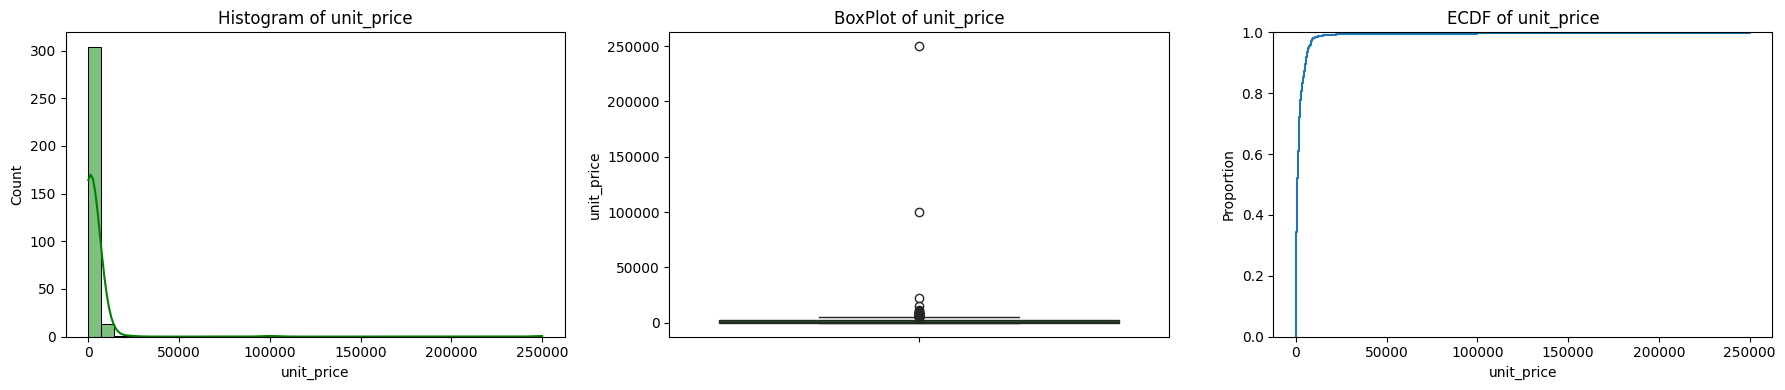

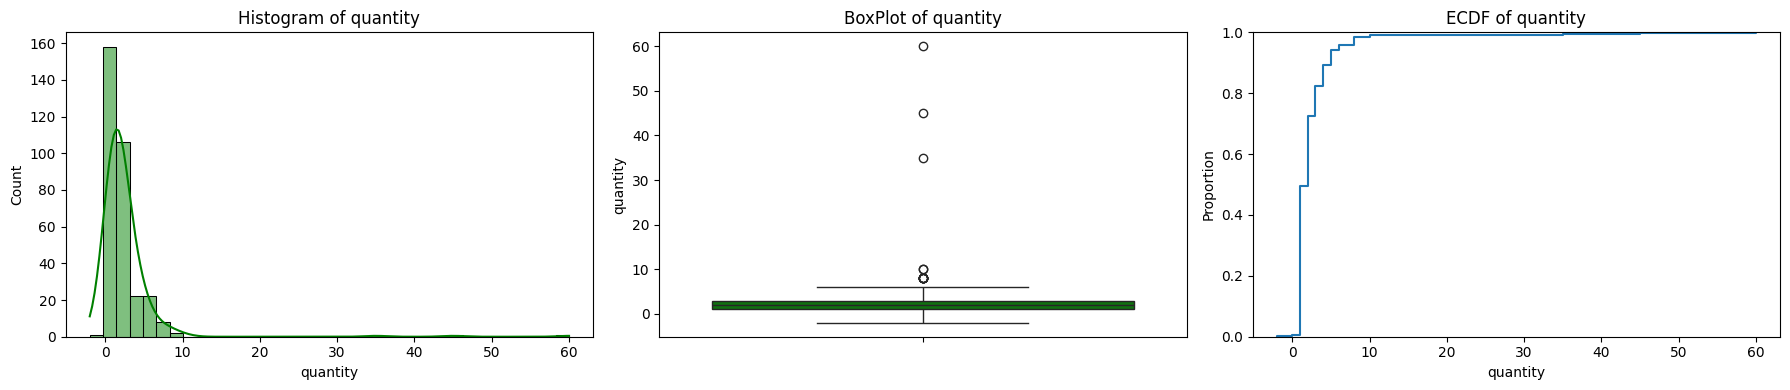

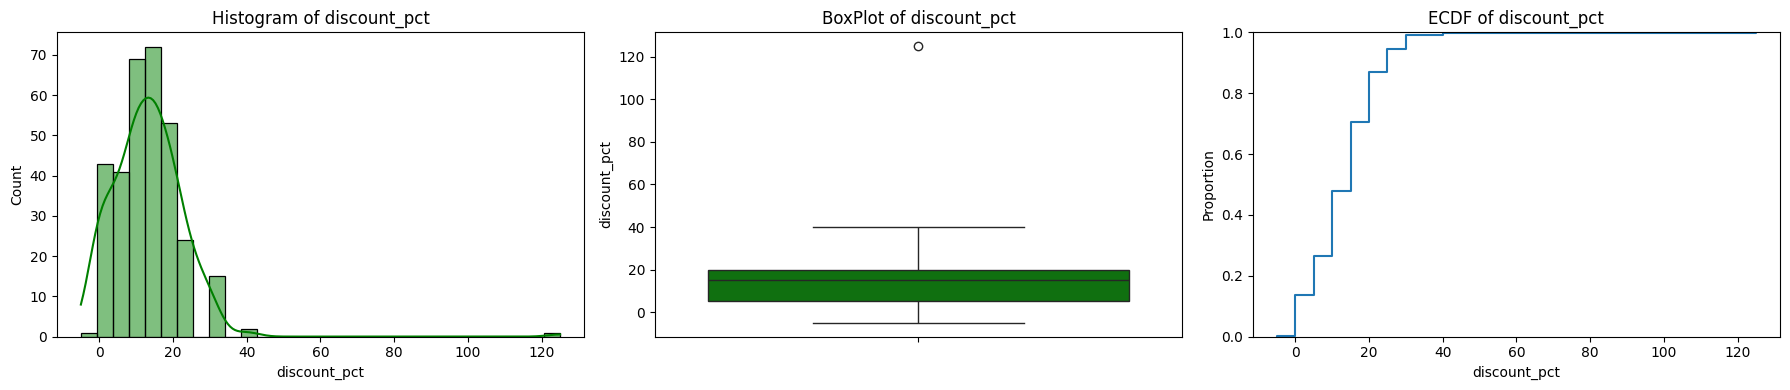

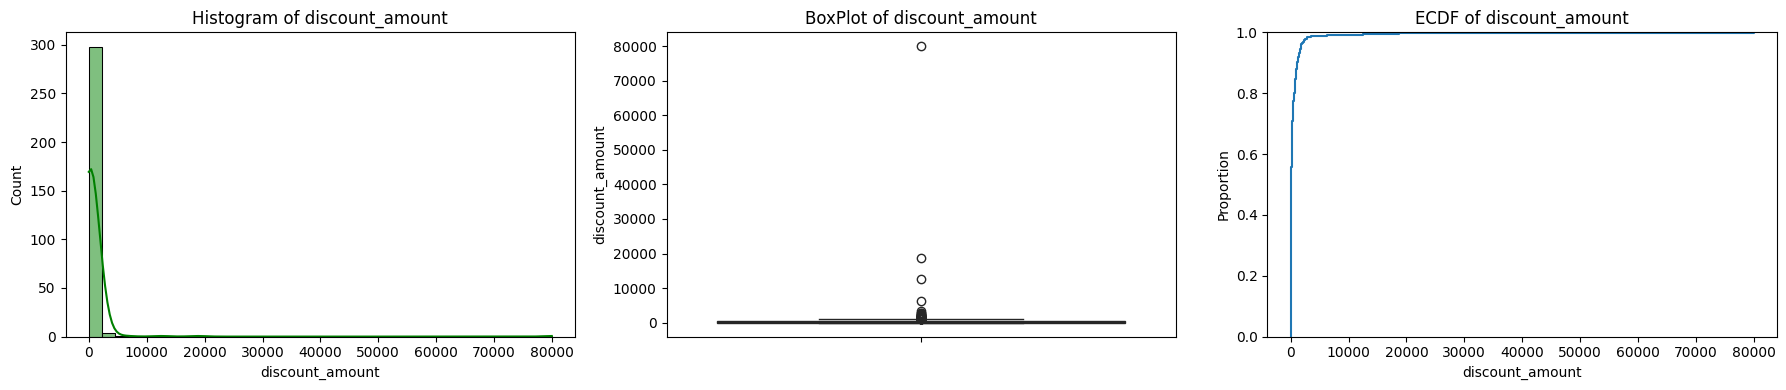

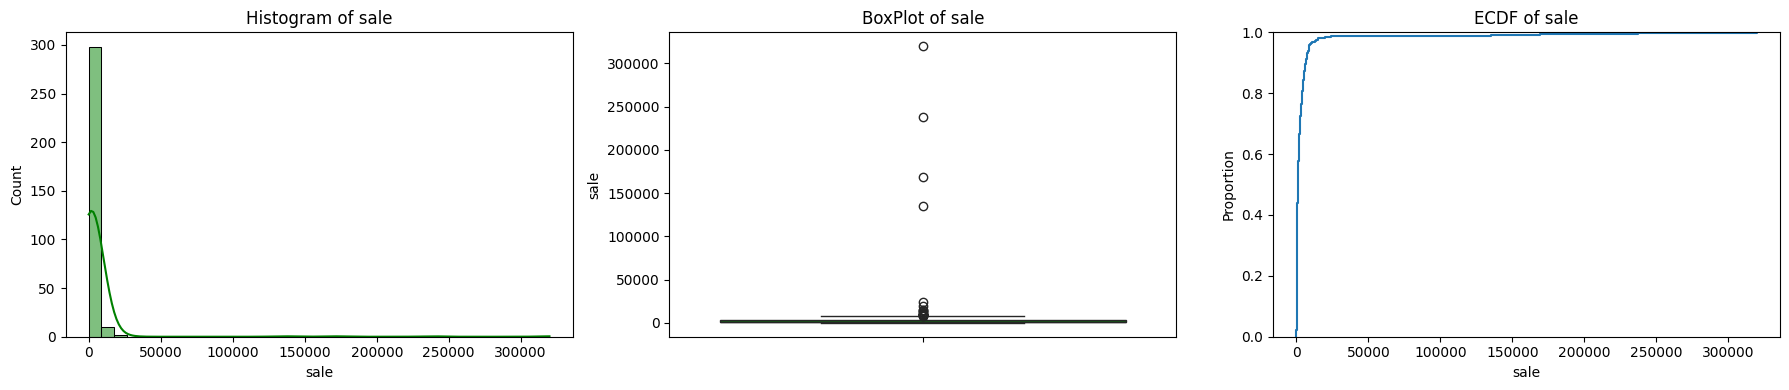

In [0]:
for i in num_col:
    s = df_clean[i]
    plt.figure(figsize=(18,4))

    plt.subplot(1,3,1)
    sns.histplot(s, color = 'green', kde=True)
    plt.title(f'Histogram of {i}')

    plt.subplot(1,3,2)
    sns.boxplot(s, color = 'green')
    plt.title(f'BoxPlot of {i}')

    plt.subplot(1,3,3)
    sns.ecdfplot(s)
    plt.title(f'ECDF of {i}')

    plt.tight_layout()
    plt.show

###Outlier flagging

In [0]:
#  IQR method for outlier flagging

q3 = df_clean['sale'].quantile(0.75)
q1 = df_clean['sale'].quantile(0.25)
iqr = q3 - q1
upper_bound = q3 + iqr*1.5
lower_bound = q1 - iqr*1.5

iqr_sale = df_clean[ (df_clean['sale'] < upper_bound) & (df_clean['sale'] > lower_bound) ]

iqr_sale_outlier = df_clean[ (df_clean['sale'] > upper_bound) | (df_clean['sale'] < lower_bound) ]
print(f'Upper Bound: {upper_bound}\nLower Bound: {lower_bound}\nOutlier flagged: {iqr_sale_outlier.shape[0]}')
iqr_sale_outlier

Upper Bound: 7344.781250000001
Lower Bound: -3906.6687500000007
Outlier flagged: 21


,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method,discount_amount,sale,sale month
12,ORD-010014,2025-12-25,CUST-0063,Bangalore,Home & Kitchen,4738.0,2,0,Delivered,UPI,0.0,9476.0,December
14,ORD-010016,NaT,CUST-0014,Pune,Home & Kitchen,452.0,35,5,Delivered,UPI,791.0,15029.0,NaN
45,ORD-010047,2026-01-06,CUST-0021,Hyderabad,Home & Kitchen,3010.0,45,0,Delivered,Credit Card,0.0,135450.0,January
63,ORD-010065,2025-10-17,CUST-0082,Mumbai,Clothing,249999.0,1,5,Delivered,UPI,12499.95,237499.05,October
105,ORD-010107,2025-10-07,CUST-0022,<NA>,Electronics,9510.0,1,5,Delivered,UPI,475.5,9034.5,October
107,ORD-010109,2026-02-16,CUST-0006,Pune,Electronics,3821.0,3,25,Delivered,Debit Card,2865.75,8597.25,February
123,ORD-010125,2025-09-14,CUST-0003,Delhi,Home & Kitchen,5248.0,4,30,Delivered,Cash On Delivery,6297.6,14694.4,September
126,ORD-010128,2025-12-22,CUST-0005,Mumbai,Electronics,10273.0,1,15,Returned,Cash On Delivery,1540.95,8732.05,December
127,ORD-010129,2025-10-10,CUST-0041,Delhi,Electronics,8477.0,1,<NA>,Delivered,Debit Card,<NA>,8477.0,October
134,ORD-010136,2026-02-10,<NA>,Bangalore,Clothing,5382.0,2,<NA>,Cancelled,Wallet,<NA>,10764.0,February


In [0]:
thresh_sale = df_clean[df_clean['sale'] < 50000]
thresh_sale_outlier = df_clean[df_clean['sale'] > 50000]
print(f'Defined threshold for sale: 50,000\nOutlier Flagged: {thresh_sale_outlier.shape[0]}')
thresh_sale_outlier

Defined threshold for sale: 50,000
Outlier Flagged: 4


,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method,discount_amount,sale,sale month
45,ORD-010047,2026-01-06,CUST-0021,Hyderabad,Home & Kitchen,3010.0,45,0,Delivered,Credit Card,0.0,135450.0,January
63,ORD-010065,2025-10-17,CUST-0082,Mumbai,Clothing,249999.0,1,5,Delivered,UPI,12499.95,237499.05,October
177,ORD-010179,2026-02-06,CUST-0001,Jaipur,Clothing,3133.0,60,10,Delivered,Credit Card,18798.0,169182.0,February
253,ORD-010255,2026-01-20,CUST-0149,Lucknow,Grocery,99999.0,4,20,Delivered,Net Banking,79999.2,319996.8,January


In [0]:
s = df_clean['sale']
q99 = s.quantile(0.99)
q01 = s.quantile(0.01)

quant_sale = df_clean[ (s < q99) & (s > q01) ]
quant_sale_outlier = df_clean[ (s > q99) | (s < q01) ]
print(f'Quantile range: {round(q01,3)} to {round(q99,3)}\nOutlier flagged: {quant_sale_outlier.shape[0]}')
quant_sale_outlier

Quantile range: 3.699 to 120938.1
Outlier flagged: 8


,order_id,order_date,customer_id,city,category,unit_price,quantity,discount_pct,order_status,payment_method,discount_amount,sale,sale month
45,ORD-010047,2026-01-06,CUST-0021,Hyderabad,Home & Kitchen,3010.0,45,0,Delivered,Credit Card,0.0,135450.0,January
63,ORD-010065,2025-10-17,CUST-0082,Mumbai,Clothing,249999.0,1,5,Delivered,UPI,12499.95,237499.05,October
115,ORD-010117,2025-11-16,CUST-0002,Delhi,Grocery,86.0,-2,10,Delivered,UPI,-17.2,-154.8,November
177,ORD-010179,2026-02-06,CUST-0001,Jaipur,Clothing,3133.0,60,10,Delivered,Credit Card,18798.0,169182.0,February
213,ORD-010215,2025-09-19,CUST-0062,Jaipur,Electronics,1.0,1,5,Delivered,Debit Card,0.05,0.95,September
236,ORD-010238,2025-08-08,CUST-0098,Pune,Beauty,689.0,1,125,Delivered,Credit Card,861.25,-172.25,August
253,ORD-010255,2026-01-20,CUST-0149,Lucknow,Grocery,99999.0,4,20,Delivered,Net Banking,79999.2,319996.8,January
313,ORD-010315,2025-09-09,CUST-0032,Mumbai,Electronics,3928.0,0,15,Failed,Credit Card,0.0,0.0,September


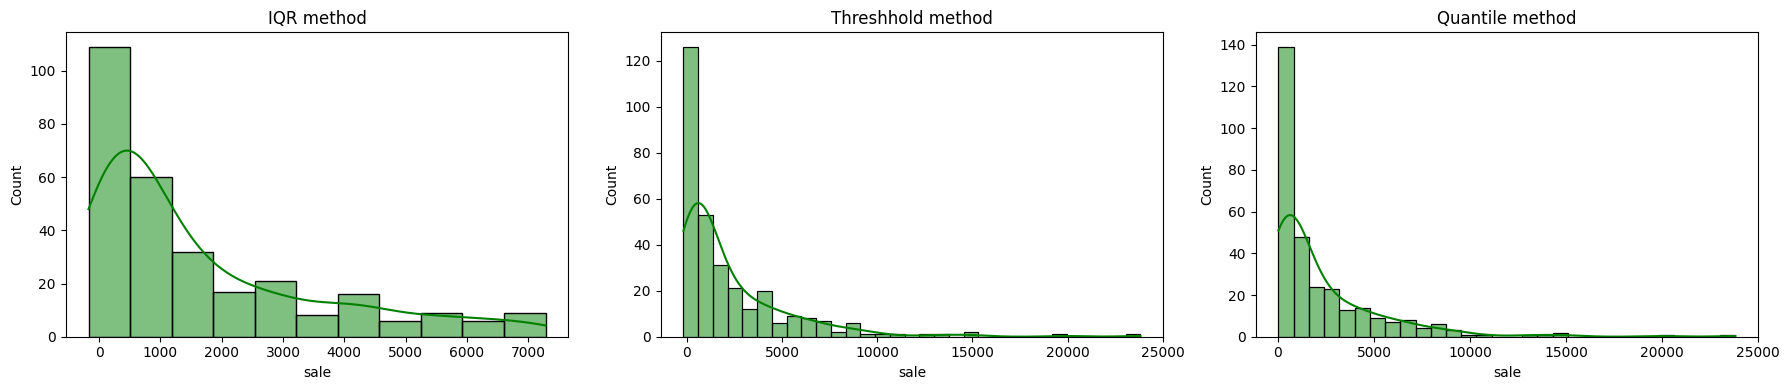

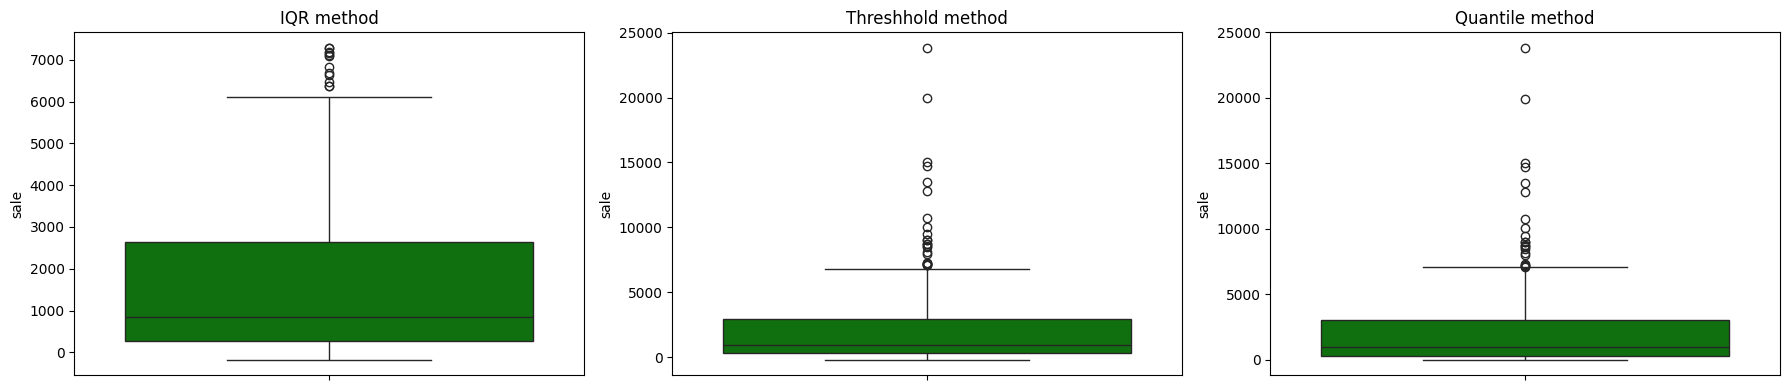

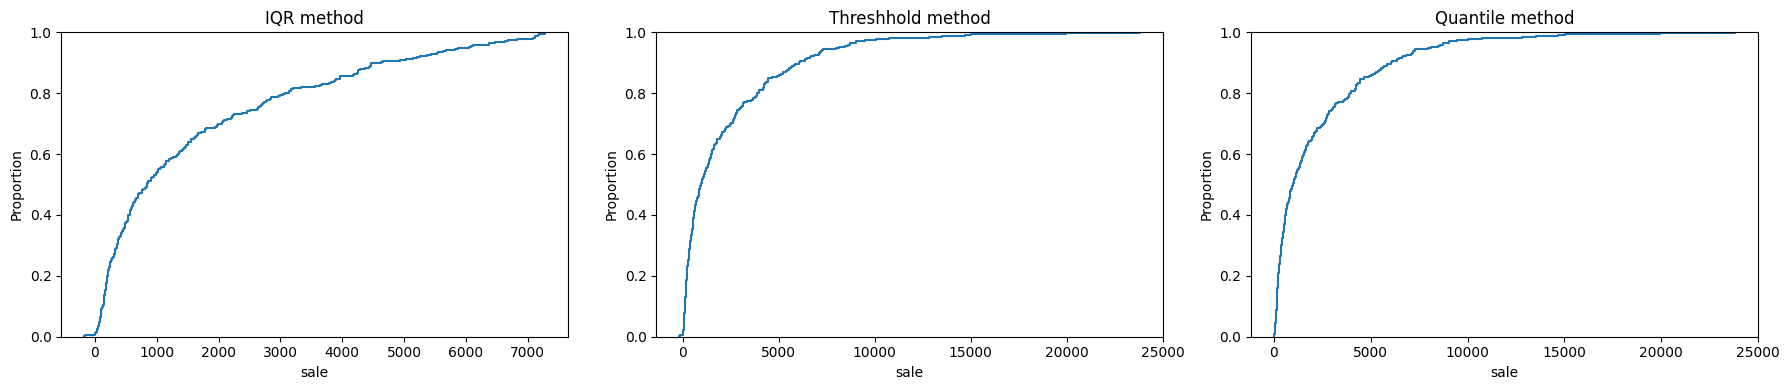

In [0]:
plt.figure(figsize=(18,4))
plt.subplot(1,3,1)
sns.histplot(iqr_sale['sale'], color = 'green', kde = True)
plt.title("IQR method")
plt.subplot(1,3,2)
sns.histplot(thresh_sale['sale'], color = 'green', kde = True)
plt.title("Threshhold method")
plt.subplot(1,3,3)
sns.histplot(quant_sale['sale'], color = 'green', kde = True)
plt.title("Quantile method")
plt.tight_layout()
plt.show()

plt.figure(figsize=(18,4))
plt.subplot(1,3,1)
sns.boxplot(iqr_sale['sale'], color = 'green')
plt.title("IQR method")
plt.subplot(1,3,2)
sns.boxplot(thresh_sale['sale'], color = 'green')
plt.title("Threshhold method")
plt.subplot(1,3,3)
sns.boxplot(quant_sale['sale'], color = 'green')
plt.title("Quantile method")
plt.tight_layout()
plt.show()

plt.figure(figsize=(18,4))
plt.subplot(1,3,1)
sns.ecdfplot(iqr_sale['sale'])
plt.title("IQR method")
plt.subplot(1,3,2)
sns.ecdfplot(thresh_sale['sale'])
plt.title("Threshhold method")
plt.subplot(1,3,3)
sns.ecdfplot(quant_sale['sale'])
plt.title("Quantile method")
plt.tight_layout()
plt.show()


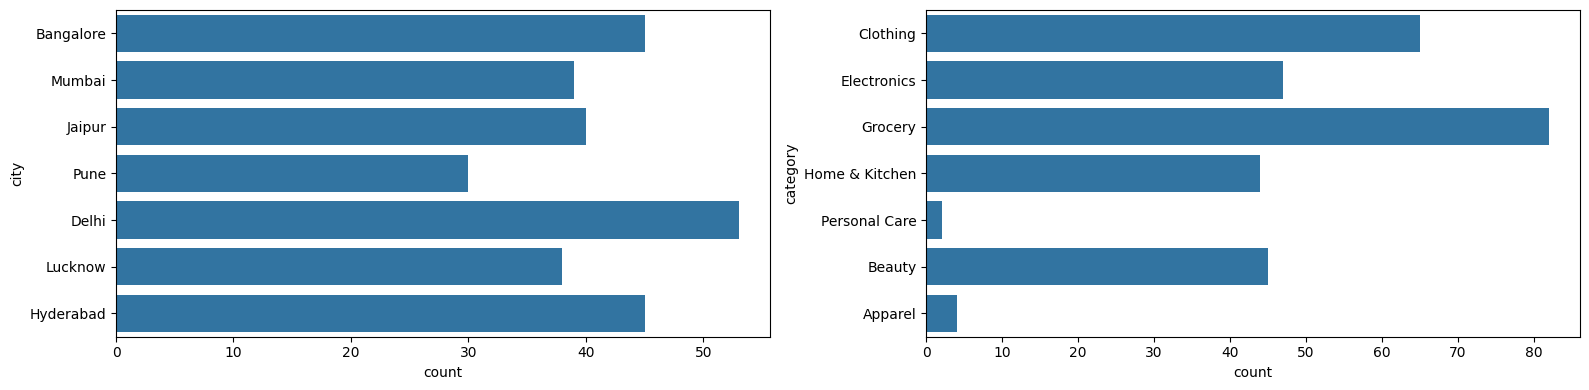

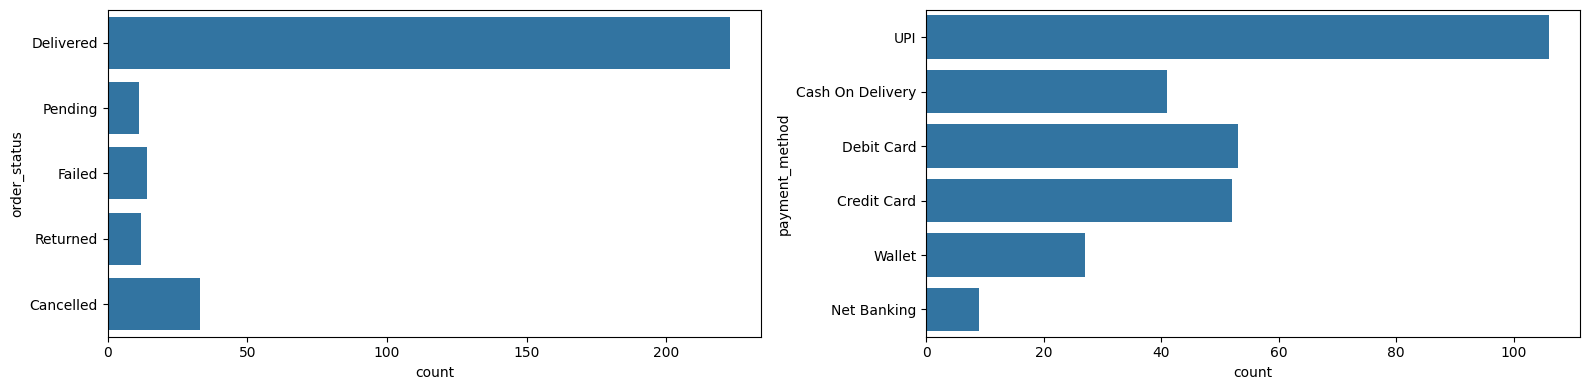

In [0]:
cat_col = ['city', 'category', 'order_status', 'payment_method']
len_cat_col = len(cat_col)
for i in range(0, len_cat_col, 2):
    plt.figure(figsize=(16,4))

    plt.subplot(1,2,1)
    sns.countplot(iqr_sale[cat_col[i]])

    plt.subplot(1,2,2)
    sns.countplot(iqr_sale[cat_col[i+1]])

    plt.tight_layout()
    plt.show()

In [0]:
monthly = (iqr_sale.dropna(subset='order_date').set_index('order_date')['sale'].resample('MS').sum(min_count = 1).rename('sale').to_frame())
monthly['absolute_change'] = monthly['sale'].diff()
monthly['pct_change'] = monthly['sale'].pct_change()*100
monthly['rolling_3M_avg'] = monthly['sale'].rolling(3, min_periods=3).mean()
monthly.dropna(subset='sale').tail(10)

/home/spark-ffb93423-94d4-4550-870d-32/.ipykernel/63/command-7360679317373796-470686844:3: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  monthly['pct_change'] = monthly['sale'].pct_change()*100


,sale,absolute_change,pct_change,rolling_3M_avg
order_date,,,,
2025-08-01,78134.4,<NA>,2856.948229,NaN
2025-09-01,51765.35,-26369.05,-33.748323,NaN
2025-10-01,65747.25,13981.9,27.010153,65215.666667
2025-11-01,77205.25,11458.0,17.427345,64905.950000
2025-12-01,67720.25,-9485.0,-12.285434,70224.250000
2026-01-01,62114.05,-5606.2,-8.278469,69013.183333
2026-02-01,62782.15,668.1,1.075602,64205.483333
2026-03-01,429.3,-62352.85,-99.316207,41775.166667
2026-09-01,1786.95,<NA>,316.247379,NaN


##Bivariate

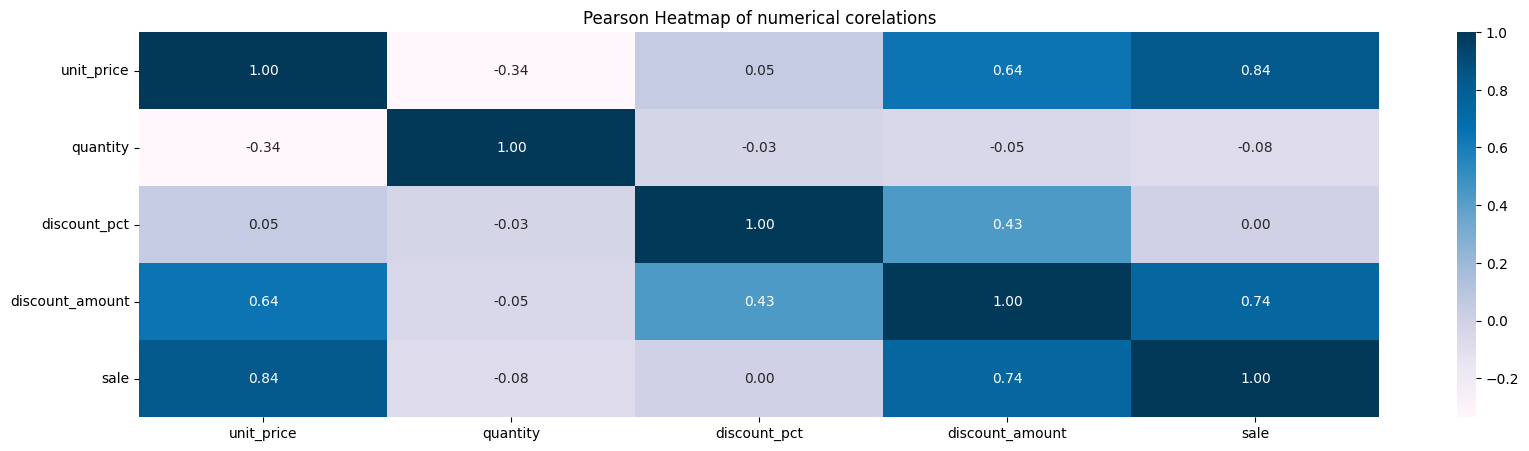

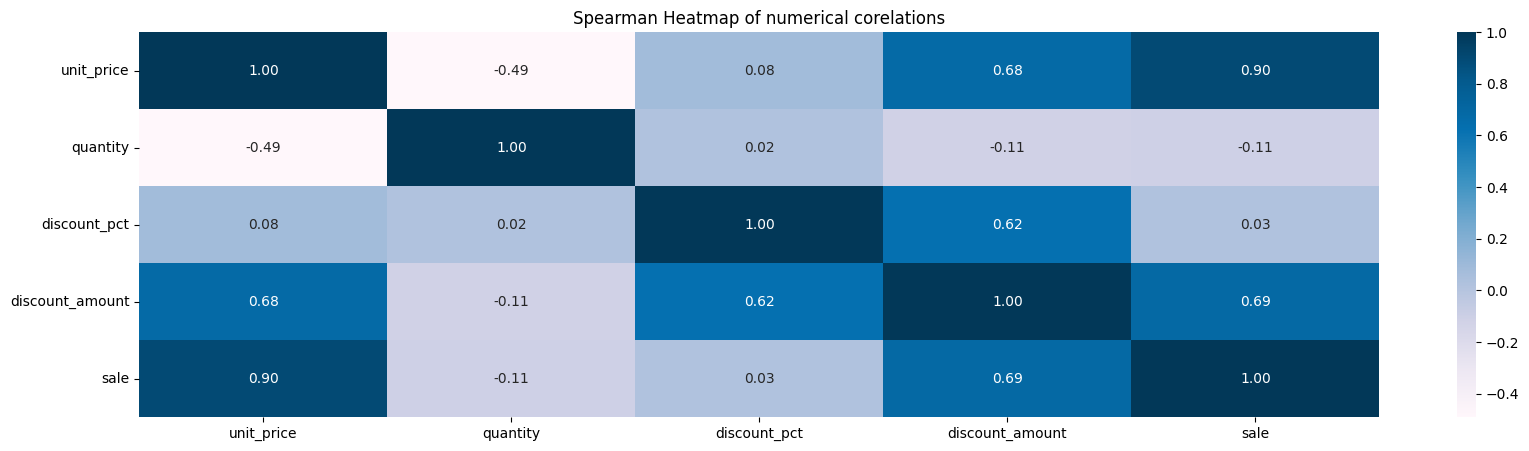

In [0]:
pearson = iqr_sale.corr(method='pearson', numeric_only=True)
spearman = iqr_sale.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(20,5))
sns.heatmap(pearson, annot = True , fmt='.2f', cmap = 'PuBu')
plt.title('Pearson Heatmap of numerical corelations')
plt.show()

plt.figure(figsize=(20,5))
sns.heatmap(spearman, annot = True,  fmt='.2f', cmap = 'PuBu')
plt.title('Spearman Heatmap of numerical corelations')
plt.show()

In [0]:
city_sale = df_clean.groupby('city')['sale'].agg(sum='sum', count="count", mean="mean", median="median", std="std", min="min", max="max")
city_sale = pd.DataFrame(city_sale)
city_sale

,sum,count,mean,median,std,min,max
city,,,,,,,
Bangalore,99640.95,47,2120.020213,646.0,2691.433309,49.3,10764.0
Delhi,118999.75,56,2124.995536,1008.9,2969.204273,-154.8,14694.4
Hyderabad,266652.3,48,5555.25625,1700.525,19450.594853,28.0,135450.0
Jaipur,226502.05,42,5392.905952,706.5,25962.002324,0.95,169182.0
Lucknow,392531.5,40,9813.2875,738.45,50354.495436,22.1,319996.8
Mumbai,347511.0,44,7897.977273,1027.55,35669.075914,0.0,237499.05
Pune,91629.7,33,2776.657576,1357.2,3389.141662,-172.25,15029.0


In [0]:
category_sale = df_clean.groupby('category')['sale'].agg(sum='sum', count="count", mean="mean", median="median", std="std", min="min", max="max")
category_sale = pd.DataFrame(category_sale)
category_sale

,sum,count,mean,median,std,min,max
category,,,,,,,
Apparel,7795.1,4,1948.775,2219.2,868.814684,716.1,2640.6
Beauty,30085.95,45,668.576667,389.0,826.152568,-172.25,4175.0
Clothing,548426.55,68,8065.096324,1508.8,34807.206919,356.4,237499.05
Electronics,308810.55,57,5417.728947,4427.95,4092.382202,0.0,23820.0
Grocery,344081.15,83,4145.556024,171.0,35093.405139,-154.8,319996.8
Home & Kitchen,299505.9,51,5872.664706,1935.0,18850.319514,204.0,135450.0
Personal Care,383.0,2,191.5,191.5,21.92031,176.0,207.0


In [0]:
payment_method_sale = df_clean.groupby('payment_method')['sale'].agg(sum='sum',count="count", mean="mean", median="median", std="std", min="min", max="max")
payment_method_sale = pd.DataFrame(payment_method_sale)
payment_method_sale

,sum,count,mean,median,std,min,max
payment_method,,,,,,,
Cash On Delivery,138100.35,46,3002.181522,1502.4,3359.80877,85.5,14694.4
Credit Card,412905.7,57,7243.959649,951.0,28284.938045,-172.25,169182.0
Debit Card,127086.35,55,2310.660909,1259.0,2431.479734,0.95,8597.25
Net Banking,325354.65,10,32535.465,607.4,101004.168982,49.6,319996.8
UPI,471831.55,113,4175.500442,631.8,22404.325938,-154.8,237499.05
Wallet,67515.7,28,2411.275,1652.8,2492.876403,77.4,10764.0


order_status      Cancelled  Delivered  Failed  Pending  Returned
payment_method                                                   
Cash On Delivery         11         29       2        2         2
Credit Card               9         44       2        2         2
Debit Card                4         52       3        1         1
Net Banking               0          6       1        1         2
UPI                      10         91       6        5         7
Wallet                    2         24       1        1         1


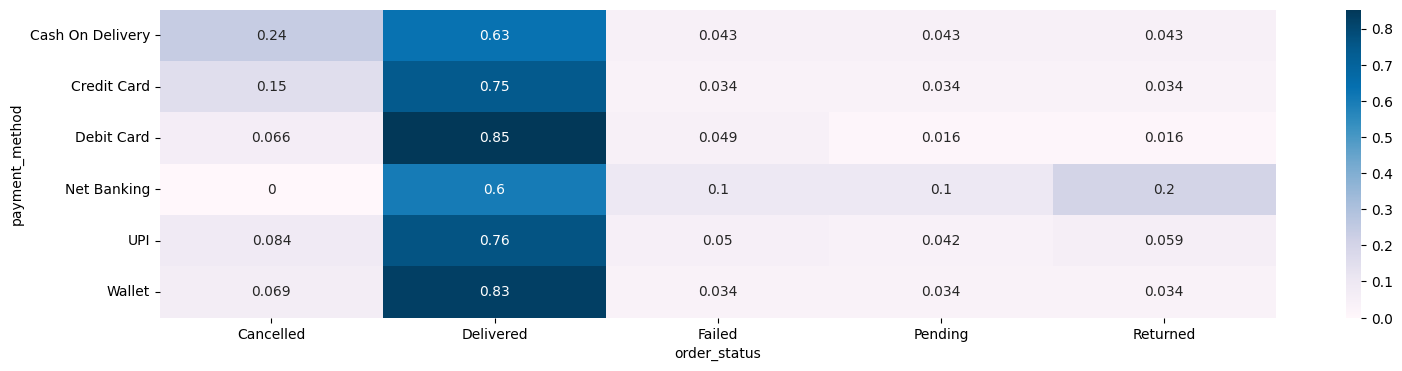

In [0]:
pay_vs_order = pd.crosstab(index = df_clean['payment_method'], columns = df_clean['order_status'])
print(pay_vs_order)

pay_vs_order_norm = pd.crosstab(index = df_clean['payment_method'], columns = df_clean['order_status'], normalize='index')
plt.figure(figsize=(18,4))
sns.heatmap(pay_vs_order_norm, annot = True, cmap = 'PuBu')
plt.show()

order_status  Cancelled  Delivered  Failed  Pending  Returned
city                                                         
Bangalore             6         41       2        1         0
Delhi                 8         46       3        2         4
Hyderabad             5         41       1        2         0
Jaipur                6         32       0        0         4
Lucknow               4         33       1        1         2
Mumbai                2         31       4        5         5
Pune                  5         25       3        0         0


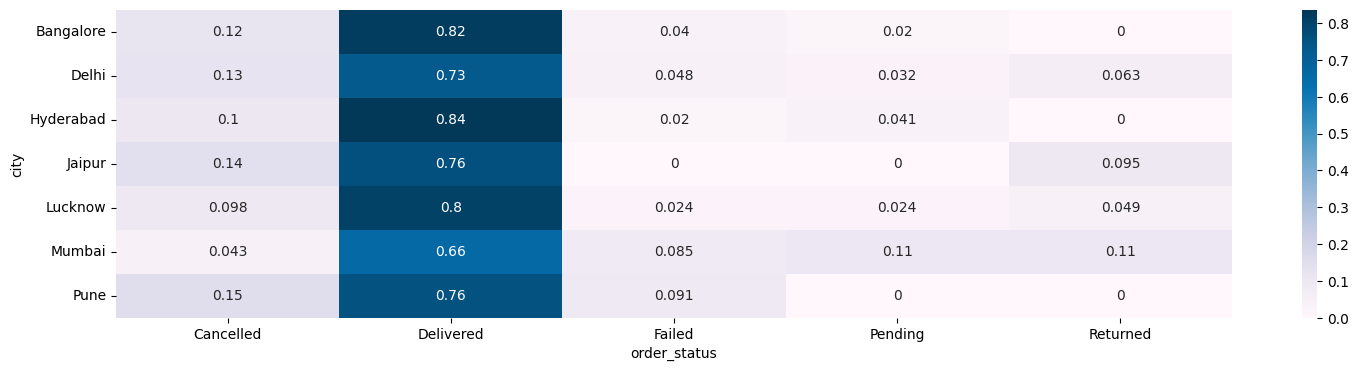

In [0]:
city_vs_order = pd.crosstab(index = df_clean['city'], columns = df_clean['order_status'])
print(city_vs_order)

city_vs_order_norm = pd.crosstab(index = df_clean['city'], columns = df_clean['order_status'], normalize='index')
plt.figure(figsize=(18,4))
sns.heatmap(city_vs_order_norm, annot = True, cmap = 'PuBu')
plt.show()

##Multivariate

category   Apparel    Beauty  Clothing  ...  Grocery  Home & Kitchen  Personal Care
city                                    ...                                        
Bangalore      0.0   3123.85   19932.1  ...  2709.15        10070.65            0.0
Delhi        716.1  11572.05  23524.45  ...  5855.75        15843.35            0.0
Hyderabad   2640.6   9570.65   17403.1  ...   1608.8         21006.2            0.0
Jaipur      1974.1    3327.7  18249.35  ...  4344.85          9808.3          207.0
Lucknow        0.0   1643.65   13957.5  ...   2649.9         11421.7          176.0
Mumbai         0.0     591.5   16464.7  ...  3342.05         11827.4            0.0
Pune        2464.3    256.55   21450.3  ...   2500.5         15257.1            0.0

[7 rows x 7 columns]


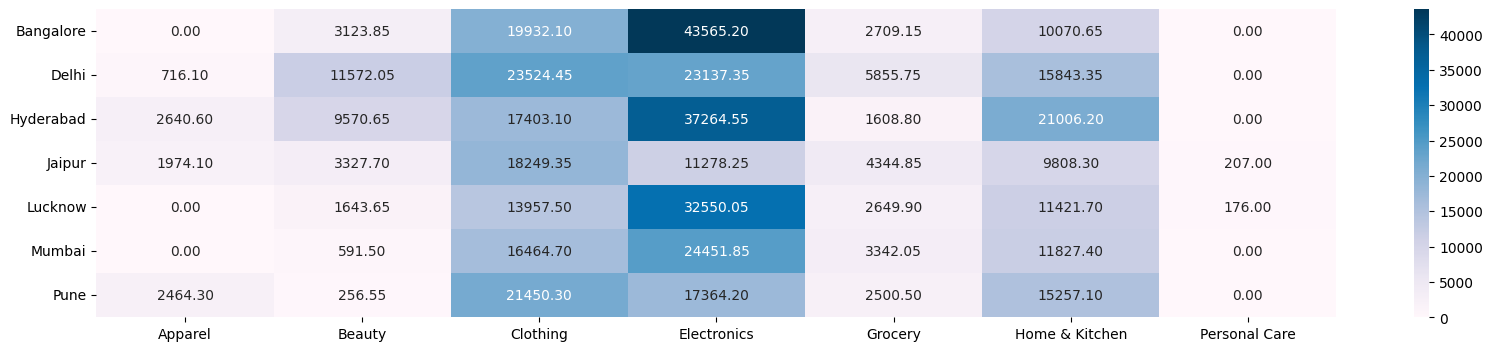

In [0]:
city_category = pd.crosstab(index = df_clean['city'], columns = df_clean['category'], values = df_clean['sale'], aggfunc = 'sum').fillna(0)

city_category2 = pd.pivot_table(iqr_sale, index = 'city', columns = 'category', values = 'sale', aggfunc = 'sum').fillna(0)

print(city_category2)

plt.figure(figsize = (20,4))
sns.heatmap(city_category2.to_numpy(dtype = 'float'), cmap = 'PuBu', annot = True, fmt = '.2f', xticklabels=city_category2.columns, yticklabels=city_category2.index)
plt.show()